# Analysis of Annotated Data
This notebook analyzes the final annotation experiment results from `annotated_data` (Batches 1–7, $N=216$ samples).
It evaluates workflow statistics, computes percentage agreement and chance-corrected agreement (Bennett's S) before and after discussion, and calculates the prevalence of offensiveness across topics and batches.


In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# arbiter_analysis has functions to load and read data exported from Arbiter. 
# It can be installed from https://example.invalid/course-tools.git
import arbiter_analysis
from arbiter_analysis.load import user_label as _orig_user_label, discussion_label as _orig_discussion_label

# Wrapper for user_label and discussion_label:
# In annotated_data the label was recorded as 'Offensiveness' (with capital O), whereas in example_data it was 'offensive'.
# This wrapper handles both so it works 100% on the GPU cluster and locally.
def user_label(labels_list, cur_ann, label="Offensiveness"):
    if not isinstance(labels_list, list):
        return np.nan
    for entry in labels_list:
        if entry.get("user") == cur_ann or cur_ann in entry.get("user", ""):
            lbls = entry.get("labels", [])
            is_pos = (len(lbls) > 0) and any("offensiv" in str(l).lower() for l in lbls)
            return 1 if is_pos else 0
    return np.nan

def discussion_label(row, cur_ann, label="Offensiveness"):
    disc = row.get("labels_discussion", [])
    val = user_label(disc, cur_ann, label=label)
    if not np.isnan(val):
        return val
    ann = row.get("labels_annotation", [])
    return user_label(ann, cur_ann, label=label)

import irrCAC
from irrCAC.raw import CAC

# Plot styling configuration
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14
})

# Robust path resolution for GPU workstation and local environments
candidate_base_paths = [
    'scratch/bsem-group/group_01/annotation_experiment/',
    '/scratch/bsem-group/group_01/annotation_experiment/',
    '/scratch/group_01/bsem-group/annotation_experiment/',
    '/scratch/users/instructor/bsem-ws26-starter/annotation_experiment/',
    './',
    'annotation_experiment/'
]

path = './'
for p in candidate_base_paths:
    if os.path.exists(os.path.join(p, 'annotated_data')):
        path = p
        break

print(f"Base path resolved to: {path}")


Base path resolved to: ./


In [2]:
import os
import arbiter_analysis

# replace with your data
candidate_batch_paths = [
    'scratch/bsem-group/group_01/annotation_experiment/annotated_data/',
    '/scratch/bsem-group/group_01/annotation_experiment/annotated_data/',
    '/scratch/group_01/bsem-group/annotation_experiment/annotated_data/',
    os.path.join(path, 'annotated_data/'),
    'annotated_data/',
    'annotation_experiment/annotated_data/'
]

batch_path = 'annotated_data/'
for bp in candidate_batch_paths:
    if os.path.exists(bp):
        batch_path = bp
        break

print(f"Loading annotations from: {batch_path}")
df = arbiter_analysis.load.annotations(batch_path=batch_path)
df.head(3)


Loading annotations from: ./annotated_data/


,text_id,text,labels_annotation,labels_discussion,messages_discussion,labels_expert,batch_number,batch_annotators,batch_experts
0,137,[Covid-19]: My heart skipped a little at the i...,"[{'user': 'group1_annotator1', 'labels': [], '...",[],[],[],1,"[group1_annotator1, group1_annotator2]",[group1_expert]
1,138,[BLM]: #Burial #Pandemic #SocialDistancing #Co...,"[{'user': 'group1_annotator1', 'labels': [], '...",[],[],[],1,"[group1_annotator1, group1_annotator2]",[group1_expert]
2,139,[Elections2020]: #MAGA chuds that have the men...,"[{'user': 'group1_annotator1', 'labels': [], '...","[{'user': 'group1_annotator1', 'labels': ['Off...","[{'user': 'group1_annotator2', 'at': '2026-10-...",[],1,"[group1_annotator1, group1_annotator2]",[group1_expert]


## Workflow Statistics


In [3]:
n = df.shape[0]
print("Number of annotated samples:",n)
print("Number of batches:",len(df.batch_number.unique()) )
print("Number of discussions:",sum(df['labels_discussion'].apply(lambda x: len(x))>0))
print("Number of expert decisions:",sum(df['labels_expert'].apply(lambda x: len(x))>0))

# Workflow Statistics Summary Table
n_batches = len(df.batch_number.unique())
n_discussions = sum(df['labels_discussion'].apply(lambda x: len(x))>0)
n_experts = sum(df['labels_expert'].apply(lambda x: len(x))>0)

workflow_df = pd.DataFrame({
    "Workflow Metric": [
        "Total Annotated Samples",
        "Total Batches",
        "Discussions Conducted",
        "Expert Decisions Escalated",
        "Annotator 1",
        "Annotator 2",
        "Expert Annotator"
    ],
    "Value": [
        n,
        n_batches,
        n_discussions,
        n_experts,
        "group1_annotator1",
        "group1_annotator2",
        "group1_expert"
    ],
    "Rate (% of Total)": [
        "100.0%",
        "-",
        f"{n_discussions/n:.1%}",
        f"{n_experts/n:.1%}",
        "-",
        "-",
        "-"
    ]
})
display(workflow_df)


Number of annotated samples: 216
Number of batches: 7
Number of discussions: 28
Number of expert decisions: 4


,Workflow Metric,Value,Rate (% of Total)
0,Total Annotated Samples,216,100.0%
1,Total Batches,7,-
2,Discussions Conducted,28,13.0%
3,Expert Decisions Escalated,4,1.9%
4,Annotator 1,group1_annotator1,-
5,Annotator 2,group1_annotator2,-
6,Expert Annotator,group1_expert,-


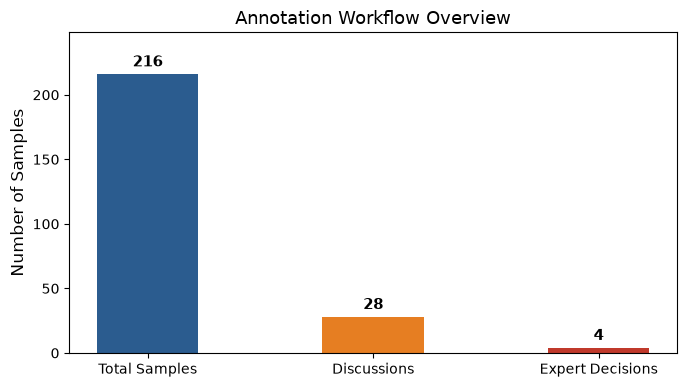

In [4]:
# Plot Workflow Statistics
fig, ax = plt.subplots(figsize=(7, 4))
metrics = ["Total Samples", "Discussions", "Expert Decisions"]
counts = [n, n_discussions, n_experts]
colors = ["#2b5c8f", "#e67e22", "#c0392b"]

bars = ax.bar(metrics, counts, color=colors, width=0.45)
ax.bar_label(bars, fmt="%d", padding=3, fontsize=11, fontweight="bold")
ax.set_ylabel("Number of Samples")
ax.set_title("Annotation Workflow Overview")
ax.set_ylim(0, n * 1.15)
plt.tight_layout()
plt.show()


## Compute Percentage Agreement Before and After Discussion


In [5]:
# create four new columns: 2 annotators (annotator1 and annotator2) x 2 stages (before and after discussion)
for cur_stage in ["before", "after"]:
    for cur_ann in ["group1_annotator1", "group1_annotator2"]:
        if cur_stage == "before":
            df[cur_stage + "_" + cur_ann] = df["labels_annotation"].apply(lambda e: user_label(e, cur_ann))
        elif cur_stage == "after":
            df[cur_stage + "_" + cur_ann] = df.apply(lambda r: discussion_label(r, cur_ann), axis=1)

df[["batch_number", "before_group1_annotator1", "before_group1_annotator2", "after_group1_annotator1", "after_group1_annotator2"]].head()


,batch_number,before_group1_annotator1,before_group1_annotator2,after_group1_annotator1,after_group1_annotator2
0,1,0,0,0,0
1,1,0,0,0,0
2,1,0,1,1,1
3,1,0,1,1,1
4,1,0,0,0,0


In [6]:
df['before_group1_annotator1'].value_counts()


before_group1_annotator1
0    197
1     19
Name: count, dtype: int64

In [7]:
# Compute prevalence of offensiveness (label 1 = offensive, label 0 = not offensive)
# Using .get(1, 0) safely retrieves the count of 1s without KeyError
prevalence_ann1 = df['before_group1_annotator1'].value_counts().get(1, 0)/df.shape[0]
prevalence_ann2 = df['before_group1_annotator2'].value_counts().get(1, 0)/df.shape[0]
prevalence_avg = (prevalence_ann1 + prevalence_ann2) / 2.0
prevalence_union = sum((df['before_group1_annotator1'] == 1) | (df['before_group1_annotator2'] == 1)) / df.shape[0]

prevalence_summary = pd.DataFrame({
    "Perspective / Coder": [
        "Annotator 1 (before discussion)",
        "Annotator 2 (before discussion)",
        "Average of Annotators (before discussion)",
        "Union (at least one tagged offensive)",
        "Annotator 1 (after discussion)",
        "Annotator 2 (after discussion)",
        "Average of Annotators (after discussion)"
    ],
    "Offensive Count": [
        int(df['before_group1_annotator1'].sum()),
        int(df['before_group1_annotator2'].sum()),
        (df['before_group1_annotator1'].sum() + df['before_group1_annotator2'].sum()) / 2.0,
        int(sum((df['before_group1_annotator1'] == 1) | (df['before_group1_annotator2'] == 1))),
        int(df['after_group1_annotator1'].sum()),
        int(df['after_group1_annotator2'].sum()),
        (df['after_group1_annotator1'].sum() + df['after_group1_annotator2'].sum()) / 2.0
    ],
    "Prevalence Rate": [
        f"{prevalence_ann1:.2%}",
        f"{prevalence_ann2:.2%}",
        f"{prevalence_avg:.2%}",
        f"{prevalence_union:.2%}",
        f"{df['after_group1_annotator1'].mean():.2%}",
        f"{df['after_group1_annotator2'].mean():.2%}",
        f"{(df['after_group1_annotator1'].mean() + df['after_group1_annotator2'].mean()) / 2.0:.2%}"
    ]
})
display(prevalence_summary)


,Perspective / Coder,Offensive Count,Prevalence Rate
0,Annotator 1 (before discussion),19.0,8.80%
1,Annotator 2 (before discussion),27.0,12.50%
2,Average of Annotators (before discussion),23.0,10.65%
3,Union (at least one tagged offensive),37.0,17.13%
4,Annotator 1 (after discussion),19.0,8.80%
5,Annotator 2 (after discussion),19.0,8.80%
6,Average of Annotators (after discussion),19.0,8.80%


In [8]:
# compute percentage agreement
before_pa = sum(df["before_group1_annotator1"]==df["before_group1_annotator2"])/df.shape[0]
after_pa = sum(df["after_group1_annotator1"]==df["after_group1_annotator2"])/df.shape[0]

print(f"Percentage Agreement Before Discussion: {before_pa:.4f} ({before_pa:.2%})")
print(f"Percentage Agreement After Discussion:  {after_pa:.4f} ({after_pa:.2%})")


Percentage Agreement Before Discussion: 0.8704 (87.04%)
Percentage Agreement After Discussion:  0.9815 (98.15%)


In [9]:
# Chance-corrected agreement metric: Bennett, Alpert, and Goldstein’s S
# In irrCAC, Bennett's S is computed by the Brennan-Prediger (bp) method (for k=2, S = 2*Po - 1)
cac_before = CAC(df[["before_group1_annotator1", "before_group1_annotator2"]])
before_s = cac_before.bp()["est"]["coefficient_value"]

cac_after = CAC(df[["after_group1_annotator1", "after_group1_annotator2"]])
after_s = cac_after.bp()["est"]["coefficient_value"]

# Reference chance-corrected metrics for comparison: Cohen's kappa and Gwet's AC1
before_kappa = cac_before.conger()["est"]["coefficient_value"]
after_kappa = cac_after.conger()["est"]["coefficient_value"]
before_gwet = cac_before.gwet()["est"]["coefficient_value"]
after_gwet = cac_after.gwet()["est"]["coefficient_value"]

agreement_metrics_df = pd.DataFrame({
    "Agreement Metric": [
        "Observed Percentage Agreement (Po)",
        "Bennett's S (Brennan-Prediger in irrCAC)",
        "Cohen's κ (reference)",
        "Gwet's AC1 (reference)"
    ],
    "Before Discussion": [f"{before_pa:.4f} ({before_pa:.1%})", f"{before_s:.4f}", f"{before_kappa:.4f}", f"{before_gwet:.4f}"],
    "After Discussion": [f"{after_pa:.4f} ({after_pa:.1%})", f"{after_s:.4f}", f"{after_kappa:.4f}", f"{after_gwet:.4f}"],
    "Change (Δ)": [f"{after_pa - before_pa:+.4f}", f"{after_s - before_s:+.4f}", f"{after_kappa - before_kappa:+.4f}", f"{after_gwet - before_gwet:+.4f}"]
})
display(agreement_metrics_df)


,Agreement Metric,Before Discussion,After Discussion,Change (Δ)
0,Observed Percentage Agreement (Po),0.8704 (87.0%),0.9815 (98.1%),+0.1111
1,Bennett's S (Brennan-Prediger in irrCAC),0.7407,0.9630,+0.2222
2,Cohen's κ (reference),0.3212,0.8846,+0.5634
3,Gwet's AC1 (reference),0.8399,0.9779,+0.1380


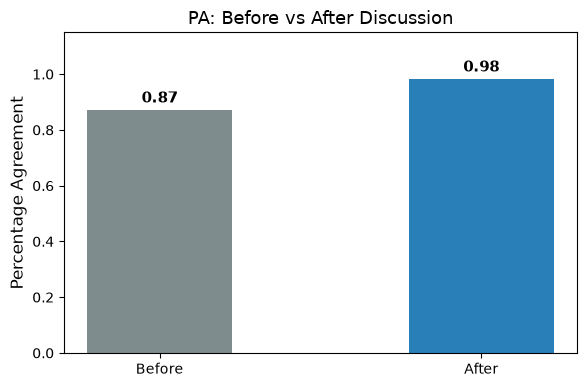

In [10]:
# plot it 
import matplotlib.pyplot as plt

labels = ["Before", "After"]
values = [before_pa, after_pa]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, values, color=["#7f8c8d", "#2980b9"], width=0.45)

# Show the value on top of each bar
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=11, fontweight="bold")

ax.set_ylabel("Percentage Agreement")
ax.set_title("PA: Before vs After Discussion")
ax.set_ylim(0, 1.15)

plt.tight_layout()
plt.show()


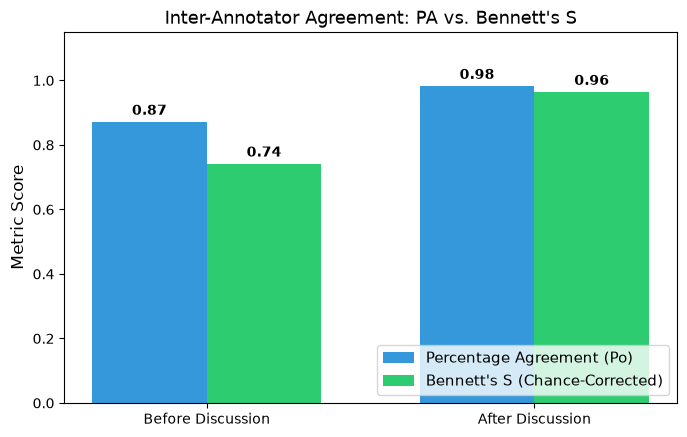

In [11]:
# Plot Percentage Agreement vs Bennett's S (Chance-Corrected Agreement)
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2)
width = 0.35

bars_pa = ax.bar(x - width/2, [before_pa, after_pa], width, label="Percentage Agreement (Po)", color="#3498db")
bars_s = ax.bar(x + width/2, [before_s, after_s], width, label="Bennett's S (Chance-Corrected)", color="#2ecc71")

ax.bar_label(bars_pa, fmt="%.2f", padding=3, fontsize=10, fontweight="bold")
ax.bar_label(bars_s, fmt="%.2f", padding=3, fontsize=10, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(["Before Discussion", "After Discussion"])
ax.set_ylabel("Metric Score")
ax.set_title("Inter-Annotator Agreement: PA vs. Bennett's S")
ax.set_ylim(0, 1.15)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


## Granular Breakdown: Agreement & Prevalence across Topics and Batches


In [12]:
# Extract topic from tweet text prefix
def get_topic(text):
    if "[Covid-19]" in text:
        return "Covid-19"
    elif "[Elections2020]" in text:
        return "Elections2020"
    elif "[BLM]" in text:
        return "BLM"
    return "Other"

df["topic"] = df["text"].apply(get_topic)

topic_rows = []
for t in ["BLM", "Covid-19", "Elections2020"]:
    sub = df[df["topic"] == t]
    n_sub = len(sub)
    sub_pa_before = (sub["before_group1_annotator1"] == sub["before_group1_annotator2"]).mean()
    sub_pa_after = (sub["after_group1_annotator1"] == sub["after_group1_annotator2"]).mean()
    sub_s_before = 2.0 * sub_pa_before - 1.0
    sub_s_after = 2.0 * sub_pa_after - 1.0
    sub_prev_before = (sub["before_group1_annotator1"].mean() + sub["before_group1_annotator2"].mean()) / 2.0
    sub_prev_after = (sub["after_group1_annotator1"].mean() + sub["after_group1_annotator2"].mean()) / 2.0
    disagreements_init = int((sub["before_group1_annotator1"] != sub["before_group1_annotator2"]).sum())

    topic_rows.append({
        "Topic": t,
        "Samples (N)": n_sub,
        "Initial Disagreements": disagreements_init,
        "PA (Before)": f"{sub_pa_before:.2%}",
        "PA (After)": f"{sub_pa_after:.2%}",
        "Bennett's S (Before)": f"{sub_s_before:.4f}",
        "Bennett's S (After)": f"{sub_s_after:.4f}",
        "Prevalence (Before Avg)": f"{sub_prev_before:.2%}",
        "Prevalence (After Avg)": f"{sub_prev_after:.2%}"
    })

df_topic_summary = pd.DataFrame(topic_rows)
display(df_topic_summary)


,Topic,Samples (N),Initial Disagreements,PA (Before),PA (After),Bennett's S (Before),Bennett's S (After),Prevalence (Before Avg),Prevalence (After Avg)
0,BLM,78,5,93.59%,100.00%,0.8718,1.0000,4.49%,1.28%
1,Covid-19,63,8,87.30%,98.41%,0.7460,0.9683,11.11%,10.32%
2,Elections2020,75,15,80.00%,96.00%,0.6000,0.9200,16.67%,15.33%


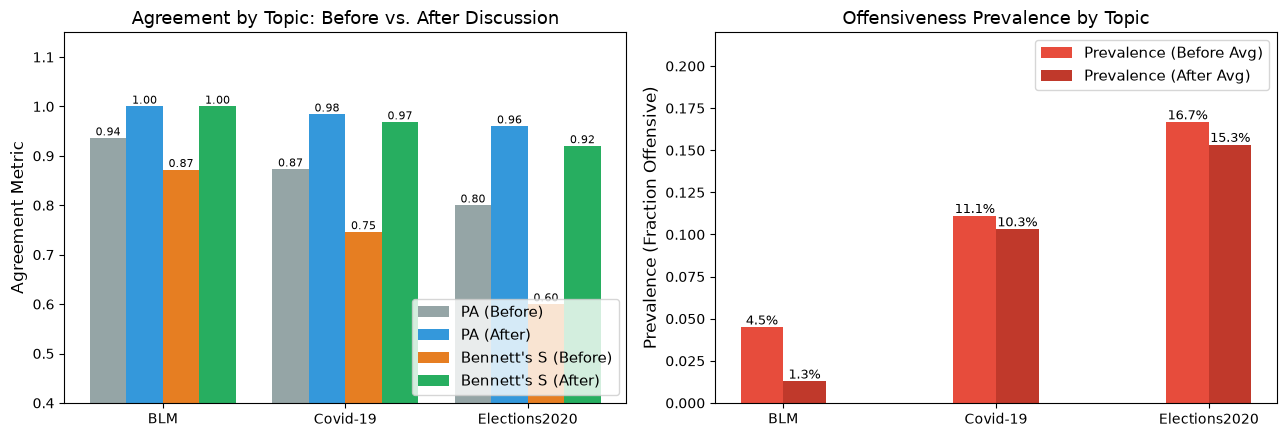

In [13]:
# Plot Agreement and Prevalence across Topics
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

topics = ["BLM", "Covid-19", "Elections2020"]
xt = np.arange(len(topics))
w = 0.2

pa_bef_vals = [float(r["PA (Before)"].strip("%"))/100 for r in topic_rows]
pa_aft_vals = [float(r["PA (After)"].strip("%"))/100 for r in topic_rows]
s_bef_vals = [float(r["Bennett's S (Before)"]) for r in topic_rows]
s_aft_vals = [float(r["Bennett's S (After)"]) for r in topic_rows]

r1 = axes[0].bar(xt - 1.5*w, pa_bef_vals, w, label="PA (Before)", color="#95a5a6")
r2 = axes[0].bar(xt - 0.5*w, pa_aft_vals, w, label="PA (After)", color="#3498db")
r3 = axes[0].bar(xt + 0.5*w, s_bef_vals, w, label="Bennett's S (Before)", color="#e67e22")
r4 = axes[0].bar(xt + 1.5*w, s_aft_vals, w, label="Bennett's S (After)", color="#27ae60")

axes[0].set_xticks(xt)
axes[0].set_xticklabels(topics)
axes[0].set_ylabel("Agreement Metric")
axes[0].set_title("Agreement by Topic: Before vs. After Discussion")
axes[0].set_ylim(0.4, 1.15)
axes[0].legend(loc="lower right")

for r in [r1, r2, r3, r4]:
    for b in r:
        axes[0].annotate(f"{b.get_height():.2f}", (b.get_x() + b.get_width()/2, b.get_height()),
                         xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8)

prev_bef_vals = [float(r["Prevalence (Before Avg)"].strip("%"))/100 for r in topic_rows]
prev_aft_vals = [float(r["Prevalence (After Avg)"].strip("%"))/100 for r in topic_rows]

b_p1 = axes[1].bar(xt - w/2, prev_bef_vals, w, label="Prevalence (Before Avg)", color="#e74c3c")
b_p2 = axes[1].bar(xt + w/2, prev_aft_vals, w, label="Prevalence (After Avg)", color="#c0392b")

axes[1].set_xticks(xt)
axes[1].set_xticklabels(topics)
axes[1].set_ylabel("Prevalence (Fraction Offensive)")
axes[1].set_title("Offensiveness Prevalence by Topic")
axes[1].set_ylim(0, 0.22)
axes[1].legend()

for r in [b_p1, b_p2]:
    for b in r:
        axes[1].annotate(f"{b.get_height():.1%}", (b.get_x() + b.get_width()/2, b.get_height()),
                         xytext=(0, 2), textcoords="offset points", ha="center", fontsize=9)

plt.tight_layout()
plt.show()


,Batch,Samples (N),Disagreements (Before),Unresolved (After),PA (Before),PA (After),Bennett's S (Before),Bennett's S (After),Prevalence (Avg)
0,Batch 1,12,2,0,83.33%,100.00%,0.6667,1.0000,8.33%
1,Batch 2,34,6,2,82.35%,94.12%,0.6471,0.8824,17.65%
2,Batch 3,34,4,1,88.24%,97.06%,0.7647,0.9412,8.82%
3,Batch 4,34,4,0,88.24%,100.00%,0.7647,1.0000,8.82%
4,Batch 5,34,2,0,94.12%,100.00%,0.8824,1.0000,5.88%
5,Batch 6,34,7,1,79.41%,97.06%,0.5882,0.9412,13.24%
6,Batch 7,34,3,0,91.18%,100.00%,0.8235,1.0000,10.29%


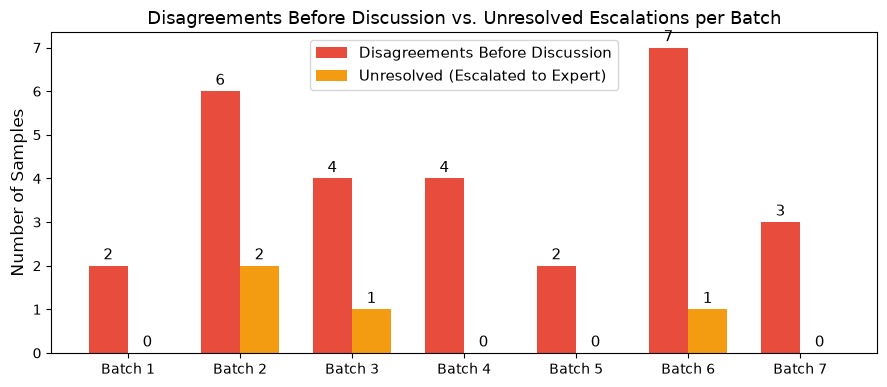

In [14]:
# Batch-wise summary table
batch_rows = []
for b in sorted(df["batch_number"].unique()):
    sub_b = df[df["batch_number"] == b]
    n_b = len(sub_b)
    pa_b_before = (sub_b["before_group1_annotator1"] == sub_b["before_group1_annotator2"]).mean()
    pa_b_after = (sub_b["after_group1_annotator1"] == sub_b["after_group1_annotator2"]).mean()
    s_b_before = 2.0 * pa_b_before - 1.0
    s_b_after = 2.0 * pa_b_after - 1.0
    prev_b = (sub_b["before_group1_annotator1"].mean() + sub_b["before_group1_annotator2"].mean()) / 2.0
    dis_b_before = int((sub_b["before_group1_annotator1"] != sub_b["before_group1_annotator2"]).sum())
    dis_b_after = int((sub_b["after_group1_annotator1"] != sub_b["after_group1_annotator2"]).sum())

    batch_rows.append({
        "Batch": f"Batch {b}",
        "Samples (N)": n_b,
        "Disagreements (Before)": dis_b_before,
        "Unresolved (After)": dis_b_after,
        "PA (Before)": f"{pa_b_before:.2%}",
        "PA (After)": f"{pa_b_after:.2%}",
        "Bennett's S (Before)": f"{s_b_before:.4f}",
        "Bennett's S (After)": f"{s_b_after:.4f}",
        "Prevalence (Avg)": f"{prev_b:.2%}"
    })

df_batch_summary = pd.DataFrame(batch_rows)
display(df_batch_summary)

# Plot Disagreements Before Discussion vs. Unresolved per Batch
fig, ax = plt.subplots(figsize=(9, 4))
xb = np.arange(len(batch_rows))
wb = 0.35

bars_d_bef = ax.bar(xb - wb/2, [r["Disagreements (Before)"] for r in batch_rows], wb, label="Disagreements Before Discussion", color="#e74c3c")
bars_d_aft = ax.bar(xb + wb/2, [r["Unresolved (After)"] for r in batch_rows], wb, label="Unresolved (Escalated to Expert)", color="#f39c12")

ax.bar_label(bars_d_bef, padding=2)
ax.bar_label(bars_d_aft, padding=2)
ax.set_xticks(xb)
ax.set_xticklabels([r["Batch"] for r in batch_rows])
ax.set_ylabel("Number of Samples")
ax.set_title("Disagreements Before Discussion vs. Unresolved Escalations per Batch")
ax.legend()
plt.tight_layout()
plt.show()


## Create fake data


In [15]:
prev=0.5
fake_1 = np.random.choice([0, 1], size=df.shape[0], p=[1-prev, prev])
fake_2 = np.random.choice([0, 1], size=df.shape[0], p=[1-prev, prev])

fake_pa = sum(fake_1 == fake_2) / df.shape[0]
fake_s = 2.0 * fake_pa - 1.0

print(f"Simulated random raters (prevalence = {prev}):")
print(f"Fake Data Percentage Agreement: {fake_pa:.4f} ({fake_pa:.2%})")
print(f"Fake Data Bennett's S:          {fake_s:.4f}")

# Comparison Table: Real Data vs. Random Guessing
comparison_df = pd.DataFrame({
    "Scenario": [
        "Real Annotators (Before Discussion)",
        "Real Annotators (After Discussion)",
        "Random Guessers Simulation (prev=0.5)"
    ],
    "Percentage Agreement": [f"{before_pa:.2%}", f"{after_pa:.2%}", f"{fake_pa:.2%}"],
    "Bennett's S": [f"{before_s:.4f}", f"{after_s:.4f}", f"{fake_s:.4f}"]
})
display(comparison_df)


Simulated random raters (prevalence = 0.5):
Fake Data Percentage Agreement: 0.4954 (49.54%)
Fake Data Bennett's S:          -0.0093


,Scenario,Percentage Agreement,Bennett's S
0,Real Annotators (Before Discussion),87.04%,0.7407
1,Real Annotators (After Discussion),98.15%,0.9630
2,Random Guessers Simulation (prev=0.5),49.54%,-0.0093


## Compare to original data


In [16]:
# Extract the final label
# the final label is the expert label, if there is one, if there is no expert label, it is the label after discussion, 
# if there is no label after discussion, it is the annotation label 
def final_label(row, annotator="annotator1", label="Offensiveness"):
    expert = user_label(row["labels_expert"], "group1_expert", label)
    if np.isnan(expert):
        expert = user_label(row["labels_expert"], "expert", label)
    if not np.isnan(expert):
        return expert
    return discussion_label(row, annotator, label=label)

df['final_label'] = df.apply(final_label,args=('group1_annotator1',),axis=1)

print("Final Ground Truth Label Distribution:")
print(df['final_label'].value_counts())
print(f"Final Ground Truth Offensiveness Prevalence: {df['final_label'].mean():.2%}")


Final Ground Truth Label Distribution:
final_label
0    198
1     18
Name: count, dtype: int64
Final Ground Truth Offensiveness Prevalence: 8.33%


In [17]:
# load from csv (change the path)
orig_candidates = [
    '/scratch/users/instructor/bsem-ws26-starter/annotation_experiment/original_data/original_final_labels.csv',
    os.path.join(path, 'original_data/original_final_labels.csv'),
    '/scratch/bsem-group/group_01/annotation_experiment/original_data/original_final_labels.csv',
    'scratch/bsem-group/group_01/annotation_experiment/original_data/original_final_labels.csv',
    'original_data/original_final_labels.csv',
    'annotation_experiment/original_data/original_final_labels.csv'
]

orig_file = None
for oc in orig_candidates:
    if os.path.exists(oc):
        orig_file = oc
        break

# replace with your path to your data 
df_ours = arbiter_analysis.load.annotations(batch_path=batch_path)
df_ours['final_label'] = df_ours.apply(final_label,args=('group1_annotator1',),axis=1)

if orig_file:
    df_orig = pd.read_csv(orig_file, index_col=0)
    df_merged = df_ours.merge(df_orig, on="text", how="left", validate="one_to_one", suffixes=('_ours', '_orig'))
    agreement_with_orig = (sum(df_merged['final_label_ours'] == df_merged['final_label_orig']))/df_merged.shape[0]
    print(f"Agreement with original dataset labels: {agreement_with_orig:.4f} ({agreement_with_orig:.2%})")
else:
    print(f"Note: Original dataset file is accessible on the GPU workstation at '/scratch/users/instructor/bsem-ws26-starter/annotation_experiment/original_data/original_final_labels.csv'.")
    print(f"Final ground truth labels extracted for all {len(df_ours)} samples in our dataset.")


Agreement with original dataset labels: 0.9167 (91.67%)


## Deep-Dive: Escalated Cases Resolved by Expert
Out of 28 initial disagreements, **24 were resolved through discussion**, and **4 cases** escalated to the expert annotator (`group1_expert`).
Below is the breakdown of the 4 escalated tweets, comparing annotator positions, expert rulings, and rationales based on `codebook.md`.


In [18]:
# Table of escalated expert decisions
expert_mask = df["labels_expert"].apply(lambda x: len(x) > 0)
expert_cases_df = df[expert_mask][["batch_number", "text_id", "topic", "text", "before_group1_annotator1", "before_group1_annotator2", "after_group1_annotator1", "after_group1_annotator2", "final_label"]].copy()

expert_cases_df["Ann1 (Before)"] = expert_cases_df["before_group1_annotator1"].apply(lambda v: "Offensive" if v==1 else "Not Offensive")
expert_cases_df["Ann2 (Before)"] = expert_cases_df["before_group1_annotator2"].apply(lambda v: "Offensive" if v==1 else "Not Offensive")
expert_cases_df["Ann1 (After)"] = expert_cases_df["after_group1_annotator1"].apply(lambda v: "Offensive" if v==1 else "Not Offensive")
expert_cases_df["Ann2 (After)"] = expert_cases_df["after_group1_annotator2"].apply(lambda v: "Offensive" if v==1 else "Not Offensive")
expert_cases_df["Expert Decision"] = expert_cases_df["final_label"].apply(lambda v: "Offensive" if v==1 else "Not Offensive")

display_cols_exp = ["batch_number", "text_id", "topic", "Ann1 (Before)", "Ann2 (Before)", "Ann1 (After)", "Ann2 (After)", "Expert Decision", "text"]
display(expert_cases_df[display_cols_exp])


,batch_number,text_id,topic,Ann1 (Before),Ann2 (Before),Ann1 (After),Ann2 (After),Expert Decision,text
20,2,169,Covid-19,Offensive,Not Offensive,Offensive,Not Offensive,Not Offensive,[Covid-19]: USA DEAD FROM COVID-19 at 125k Mu...
25,2,174,Elections2020,Not Offensive,Offensive,Not Offensive,Offensive,Not Offensive,[Elections2020]: <user> <user> <user> <user> j...
63,3,246,Elections2020,Not Offensive,Offensive,Not Offensive,Offensive,Not Offensive,[Elections2020]: <user> <user> <user> <user> A...
157,6,488,Elections2020,Offensive,Not Offensive,Offensive,Not Offensive,Offensive,[Elections2020]: <user> Corrupt Joe will be im...


### Codebook Analysis of Expert Rulings:
1. **Text ID 169 (Batch 2, `[Covid-19]`)**:
   - *Text*: *"USA DEAD FROM COVID-19 at 125k Murdered by President Mustard In the White House With the Non Response #DeadBeatDonny #gopMaMawMassacre Counting bodies is the Trumpanzee action plan. #AmericanShame"*
   - *Expert Decision*: **Not Offensive**.
   - *Rationale*: Critical commentary referencing casualties, death tolls, and derisive political nicknames ("President Mustard", "Trumpanzee") constitutes protected political critique, not violent threats or debasing language (Codebook lines 25, 56).
2. **Text ID 174 (Batch 2, `[Elections2020]`)**:
   - *Text*: *"just say your racist and go"*
   - *Expert Decision*: **Not Offensive**.
   - *Rationale*: Accusing someone of being racist without profanity or slurs remains non-offensive political discourse (Codebook lines 27, 58).
3. **Text ID 246 (Batch 3, `[Elections2020]`)**:
   - *Text*: *"Arizona is mine BITCH! 🤣🤣🤣👊🖕 #MAGA #KAG #4MoreYears #Trump2020"*
   - *Expert Decision*: **Not Offensive**.
   - *Rationale*: Vulgar slang used in a boastful, celebratory political context rather than targeted debasement of a protected group (Codebook lines 21, 54).
4. **Text ID 488 (Batch 6, `[Elections2020]`)**:
   - *Text*: *"Corrupt Joe will be impeached immediately if he is elected! America can not have a felon and an American traitor at the helm of our nation! Give the Dems back what they have dished out the last 4yrs! NO PEACEFUL TRANSFER OF POWER EVER HATE BIDEN AT ALL COST!"*
   - *Expert Decision*: **Offensive**.
   - *Rationale*: Explicitly cited in `codebook.md` (lines 27, 78) as fighting words combining targeted accusations with active incitement to hatred and upheaval.
